[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cCoolBoox/IFCD107-alumnado/blob/main/sprints/S08/2_Practica/para_casa/S08_04_svm.ipynb)

# S08 · 04 — Máquinas de vectores de soporte (SVM)

🏠 Cuaderno para casa · ⏱ ≈ 40 min · Sprint 8 · M3 (UD 3.8)

**Contexto TurisData.** Última familia del duelo: las **SVM**. Buscan la frontera que separa las clases con el **mayor margen posible** y, con el «truco del núcleo» (*kernel*), pueden dibujar fronteras curvas. Son potentes con pocos datos y muchas variables, pero **escalan mal** cuando hay muchas filas y son poco explicables. Vamos a comprobarlo con las reservas.

**Este cuaderno tiene 4 ejercicios y un mini-reto** y es **solo para casa**: no tiene versión «en clase». Es refuerzo: el reto del sprint se hace en clase y no depende de este cuaderno. Hazlo en casa, a tu ritmo y por orden.

**Cómo usar este cuaderno** (tiene dos partes):

- **Parte A · Ejecutar** (aquí abajo): de arriba abajo, cada celda de código lleva encima su título con un símbolo:
    - ⚙️ **Preparación**: se ejecuta sola, pulsa ▶ y sigue.
    - 👀 **Ejemplo**: pulsa ▶, mira el resultado y responde las preguntas 🧠 (no hay que escribir código). Las respuestas están en la Parte B.
    - ✏️ **Ejercicio**: tu turno. Cambia los `...` y pulsa ▶. Si sale **✔**, responde las preguntas 🧠 y sigues. Para comprobar tu código, tienes la solución de referencia ✅ en la Parte B.
- **Parte B · Explicación** (al final): para cada celda, **qué hace**, **qué resultado debe salir** y, en los ejemplos, las **respuestas** a las preguntas 🧠 y, en los ejercicios, la **solución de referencia** ✅ para comprobar tu código. Ábrela cuando quieras entender una celda, comprobar tus respuestas o no te salga. Usa el índice de la izquierda (☰) para saltar.

# Parte A · Ejecutar

### ⚙️ A1 · PREPARACIÓN — se ejecuta sola

Pulsa ▶ y sigue. No hace falta leerla.

In [2]:
#@title A1 · ▶ Ejecuta esta celda primero (no hace falta leerla)
import os, urllib.request

BASE_URL = "https://raw.githubusercontent.com/cCoolBoox/IFCD107-alumnado/main/datos/"

def dato(nombre):
    """Devuelve la ruta local de un archivo de datos del curso (lo descarga si no está)."""
    for carpeta in ("datos", "../datos", "../../datos", "../../../datos"):
        ruta = os.path.join(carpeta, nombre)
        if os.path.exists(ruta):
            return ruta
    os.makedirs("datos", exist_ok=True)
    ruta = os.path.join("datos", nombre)
    urllib.request.urlretrieve(BASE_URL + nombre, ruta)
    return ruta

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.svm import SVC
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
SEMILLA = 42
sns.set_theme(style="whitegrid")
print("Listo ✔")

Listo ✔


### ⚙️ A2 · PREPARACIÓN — se ejecuta sola

Pulsa ▶ y sigue. No hace falta leerla.

In [3]:
Xm, ym = make_moons(n_samples=400, noise=0.3, random_state=SEMILLA)
Xm_train, Xm_test, ym_train, ym_test = train_test_split(Xm, ym, test_size=0.3, random_state=SEMILLA)

def dibujar_frontera(modelo, ax, titulo):
    xx, yy = np.meshgrid(np.linspace(-2, 3, 200), np.linspace(-1.5, 2, 200))
    zz = modelo.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.25, cmap="coolwarm")
    ax.scatter(Xm_train[:, 0], Xm_train[:, 1], c=ym_train, cmap="coolwarm", edgecolor="k", s=25)
    ax.set(title=titulo, xlabel="Variable 1", ylabel="Variable 2")

### ✏️ A3 · EJERCICIO 1 de 4 — SVM lineal frente a SVM RBF en las dos lunas

**Tu turno:** Entrena en `Xm_train, ym_train` una SVM lineal (`svm_lineal = SVC(kernel="linear", C=1)`) y una RBF (`svm_rbf = SVC(kernel="rbf", C=1, gamma=1)`). Guarda `acc_lineal` y `acc_rbf` (exactitud en `Xm_test, ym_test` con `.score`) y en `n_soporte_rbf` el número de vectores de soporte de la RBF (`svm_rbf.n_support_.sum()`).

**Debe salir:** ✔ Ejercicio 1 correcto y dos gráficos con la frontera: recta (exactitud test 0,81) frente a curva (0,91)

Cambia los `...` y pulsa ▶.

🧠 **Autoejercicio:** cuando salga ✔, responde (respuestas en la Parte B, A3).

1. ¿Qué exactitud tienen la SVM lineal y la RBF en test?
2. ¿Cuántos vectores de soporte tiene la RBF y qué proporción son?
3. ¿Por qué la lineal rinde peor en las lunas?

✅ ¿Dudas de tu código? Compáralo con la solución de referencia en la Parte B, A3, **después de intentarlo**.

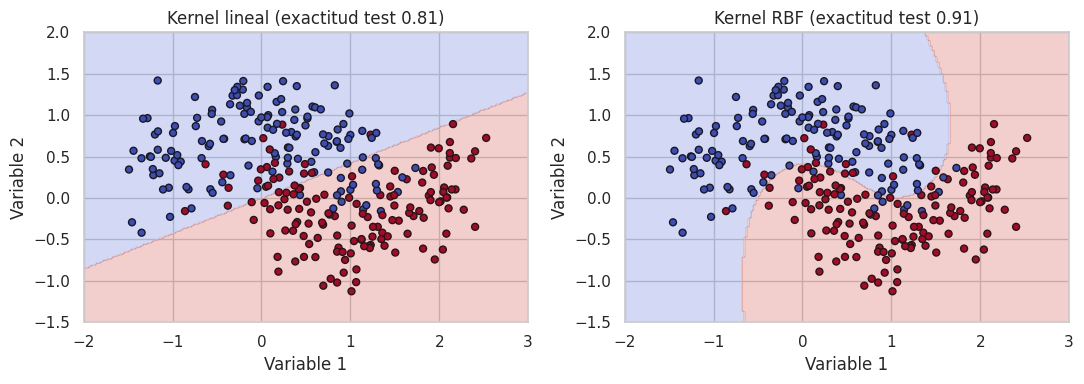

✔ Ejercicio 1 correcto


In [4]:
# pista: SVC(kernel=...).fit(Xm_train, ym_train); .score(Xm_test, ym_test)
svm_lineal = SVC(kernel="linear", C=1).fit(Xm_train, ym_train)
svm_rbf = SVC(kernel="rbf", C=1, gamma=1).fit(Xm_train, ym_train)
acc_lineal = svm_lineal.score(Xm_test, ym_test)
acc_rbf = svm_rbf.score(Xm_test, ym_test)
n_soporte_rbf = int(svm_rbf.n_support_.sum())

assert acc_rbf > acc_lineal, "En las dos lunas, el kernel RBF (curvo) debería superar al lineal"
assert 0 < n_soporte_rbf < len(Xm_train), "Los vectores de soporte son un subconjunto de los puntos"

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
dibujar_frontera(svm_lineal, ejes[0], f"Kernel lineal (exactitud test {acc_lineal:.2f})")
dibujar_frontera(svm_rbf, ejes[1], f"Kernel RBF (exactitud test {acc_rbf:.2f})")
plt.tight_layout()
plt.show()
print("✔ Ejercicio 1 correcto")

### 👀 A4 · EJEMPLO — El efecto de gamma en la frontera

Pulsa ▶ y mira lo que sale. **No hay que escribir nada.**

🧠 **Autoejercicio:** mira el resultado y responde (respuestas en la Parte B, A4).

1. ¿Qué exactitud en train y en test tiene el modelo con `gamma = 50`?
2. ¿Qué pasa con la frontera cuando `gamma` es muy grande?
3. ¿Y cuando `gamma` es muy pequeño?

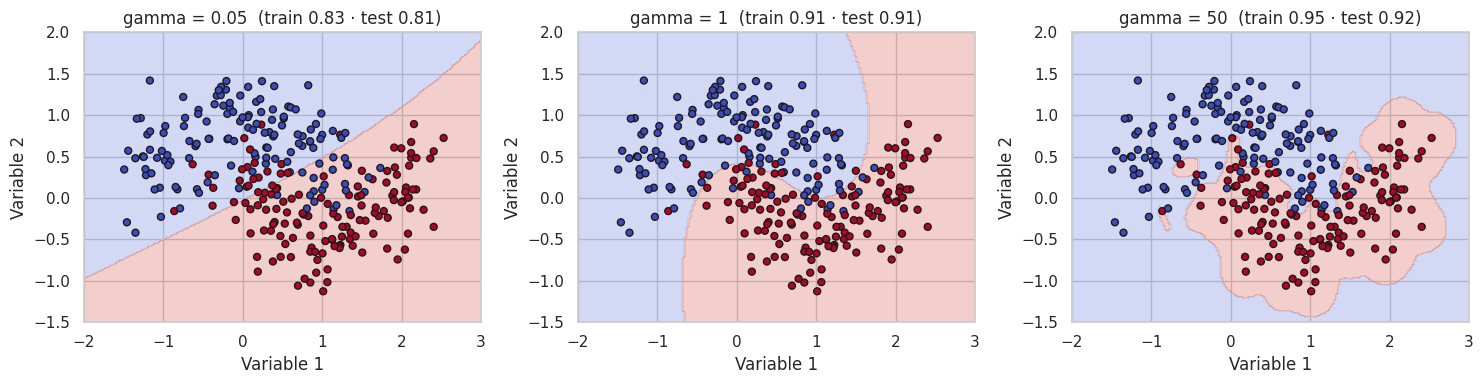

In [5]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for ax, g in zip(ejes, [0.05, 1, 50]):
    m = SVC(kernel="rbf", C=1, gamma=g).fit(Xm_train, ym_train)
    dibujar_frontera(m, ax, f"gamma = {g}  (train {m.score(Xm_train, ym_train):.2f} · test {m.score(Xm_test, ym_test):.2f})")
plt.tight_layout()
plt.show()

### ⚙️ A5 · PREPARACIÓN — se ejecuta sola

Pulsa ▶ y sigue. No hace falta leerla.

In [6]:
df = pd.read_csv(dato("reservas_turisdata.csv"), parse_dates=["fecha_reserva", "fecha_llegada"])
df["temporada_alta"] = df["fecha_llegada"].dt.month.isin([1, 2, 3, 7, 8, 12]).astype(int)
columnas_num = ["antelacion_dias", "noches", "adultos", "ninos", "precio_noche",
                "peticiones_especiales", "cliente_repetidor", "cancelaciones_previas", "temporada_alta"]
columnas_cat = ["tipo_habitacion", "regimen", "canal", "pais_origen", "tarifa", "deposito"]
X, y = df[columnas_num + columnas_cat], df["cancelada"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEMILLA, stratify=y)


def prep_escalado():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), columnas_num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), columnas_cat),
    ])

def prep_sin_escalar():
    return ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), columnas_num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), columnas_cat),
    ])

### ✏️ A6 · EJERCICIO 2 de 4 — El AUC con y sin escalado

**Tu turno:** Crea `svm_rbf_res = Pipeline([("prep", prep_escalado()), ("svm", SVC(kernel="rbf", C=1))])` y `svm_rbf_sin = Pipeline([("prep", prep_sin_escalar()), ("svm", SVC(kernel="rbf", C=1))])`. Ajústalos con train y guarda `auc_con_escalado` y `auc_sin_escalado`: el AUC en test con `decision_function`.

**Debe salir:** `AUC con escalado: 0.735 · sin escalar: 0.671` y ✔ Ejercicio 2 correcto

Cambia los `...` y pulsa ▶.

🧠 **Autoejercicio:** cuando salga ✔, responde (respuestas en la Parte B, A6).

1. ¿Qué AUC tiene la SVM con escalado y sin escalar?
2. ¿Cuánto se pierde sin escalar?
3. ¿Por qué escalar es obligatorio en una SVM?

✅ ¿Dudas de tu código? Compáralo con la solución de referencia en la Parte B, A6, **después de intentarlo**.

In [8]:
# pista: roc_auc_score(y_test, modelo.decision_function(X_test))
svm_rbf_res = Pipeline([("prep", prep_escalado()), ("svm", SVC(kernel="rbf", C=1))]).fit(X_train, y_train)
svm_rbf_sin = Pipeline([("prep", prep_sin_escalar()), ("svm", SVC(kernel="rbf", C=1))]).fit(X_train, y_train)
auc_con_escalado = roc_auc_score(y_test, svm_rbf_res.decision_function(X_test))
auc_sin_escalado = roc_auc_score(y_test, svm_rbf_sin.decision_function(X_test))
print(f"AUC con escalado: {auc_con_escalado:.3f} · sin escalar: {auc_sin_escalado:.3f}")


assert auc_con_escalado > auc_sin_escalado + 0.03, "Escalar debería mejorar claramente el AUC de la SVM"
assert auc_con_escalado > 0.70
print(f"AUC con escalado: {auc_con_escalado:.3f} · sin escalar: {auc_sin_escalado:.3f}")
print("✔ Ejercicio 2 correcto")

AUC con escalado: 0.735 · sin escalar: 0.671
AUC con escalado: 0.735 · sin escalar: 0.671
✔ Ejercicio 2 correcto


### ⚙️ A7 · PREPARACIÓN — se ejecuta sola

Pulsa ▶ y sigue. No hace falta leerla.

In [9]:
sub_X = X_train.sample(1500, random_state=SEMILLA)
sub_y = y_train.loc[sub_X.index]
rejilla = {"svm__C": [0.1, 1, 10], "svm__gamma": [0.003, 0.01, 0.03]}
cv = StratifiedKFold(3, shuffle=True, random_state=SEMILLA)

### ✏️ A8 · EJERCICIO 3 de 4 — Buscar los mejores C y gamma

**Tu turno:** Crea `busqueda = GridSearchCV(Pipeline([("prep", prep_escalado()), ("svm", SVC(kernel="rbf"))]), rejilla, cv=cv, scoring="roc_auc")` y ajústala con `sub_X, sub_y`. Guarda `mejores_params` (`busqueda.best_params_`) y `mejor_auc_cv` (`busqueda.best_score_`).

**Debe salir:** `Mejores parámetros: {'svm__C': 10, 'svm__gamma': 0.003} · AUC CV = 0.752` y ✔ Ejercicio 3 correcto

Cambia los `...` y pulsa ▶.

🧠 **Autoejercicio:** cuando salga ✔, responde (respuestas en la Parte B, A8).

1. ¿Qué `C` y `gamma` salen y qué AUC tienen?
2. ¿Cuántos modelos ha entrenado `GridSearchCV` en total?
3. ¿Por qué se hace con una submuestra de 1500 reservas?

✅ ¿Dudas de tu código? Compáralo con la solución de referencia en la Parte B, A8, **después de intentarlo**.

Mejores parámetros: {'svm__C': 10, 'svm__gamma': 0.003} · AUC CV = 0.752


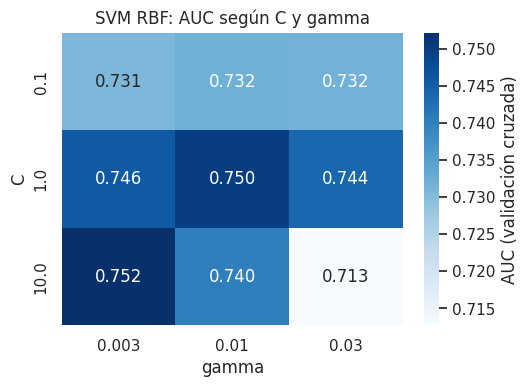

Mejores parámetros: {'svm__C': 10, 'svm__gamma': 0.003} · AUC CV = 0.752
✔ Ejercicio 3 correcto


In [10]:
# pista: GridSearchCV(pipeline, rejilla, cv=cv, scoring="roc_auc").fit(sub_X, sub_y)
busqueda = GridSearchCV(Pipeline([("prep", prep_escalado()), ("svm", SVC(kernel="rbf"))]),
                        rejilla, cv=cv, scoring="roc_auc").fit(sub_X, sub_y)
mejores_params = busqueda.best_params_
mejor_auc_cv = busqueda.best_score_
print("Mejores parámetros:", mejores_params, f"· AUC CV = {mejor_auc_cv:.3f}")

resultados = pd.DataFrame(busqueda.cv_results_)
tabla_grid = resultados.pivot_table(index="param_svm__C", columns="param_svm__gamma", values="mean_test_score").astype(float)
plt.figure(figsize=(5.5, 3.8))
sns.heatmap(tabla_grid, annot=True, fmt=".3f", cmap="Blues", cbar_kws={"label": "AUC (validación cruzada)"})
plt.title("SVM RBF: AUC según C y gamma")
plt.xlabel("gamma")
plt.ylabel("C")
plt.show()

assert set(mejores_params) == {"svm__C", "svm__gamma"}, "best_params_ debe contener C y gamma"
assert 0.65 < mejor_auc_cv < 0.85
print("Mejores parámetros:", mejores_params, f"· AUC CV = {mejor_auc_cv:.3f}")
print("✔ Ejercicio 3 correcto")

### 👀 A9 · EJEMPLO — Mapa de calor del AUC según C y gamma

Pulsa ▶ y mira lo que sale. **No hay que escribir nada.**

🧠 **Autoejercicio:** mira el resultado y responde (respuestas en la Parte B, A9).

1. ¿Qué combinación da el mejor AUC y cuál el peor?
2. ¿Qué pasa en la esquina `C = 10`, `gamma = 0.03`?
3. ¿Qué diferencia hay entre el mejor y el peor AUC?

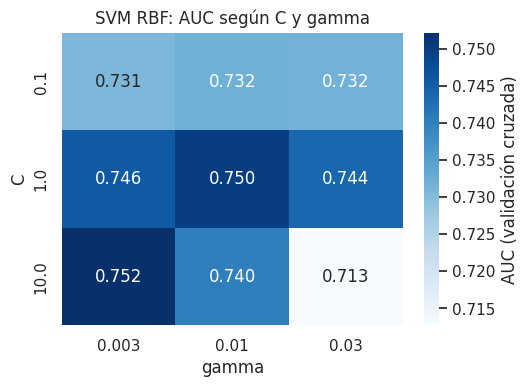

In [11]:
resultados = pd.DataFrame(busqueda.cv_results_)
tabla_grid = resultados.pivot_table(index="param_svm__C", columns="param_svm__gamma", values="mean_test_score").astype(float)
plt.figure(figsize=(5.5, 3.8))
sns.heatmap(tabla_grid, annot=True, fmt=".3f", cmap="Blues", cbar_kws={"label": "AUC (validación cruzada)"})
plt.title("SVM RBF: AUC según C y gamma")
plt.xlabel("gamma")
plt.ylabel("C")
plt.show()

### ✏️ A10 · EJERCICIO 4 de 4 — Cuánto crece el tiempo con el número de filas

**Tu turno:** Mide en `segundos` el tiempo de ajuste de `SVC(kernel="rbf", C=1, gamma=0.01)` sobre los datos ya preparados `Z` con `tamanos = [500, 1000, 2000, 4000]` (las primeras `n` filas de `Z`). Guarda en `factor_x4` cuántas veces más tarda con 4000 filas que con 1000 (`segundos[-1] / segundos[1]`).

**Debe salir:** `Segundos: [0.01, 0.02, 0.09, 0.47] · 4× filas → 19.2× tiempo` y ✔ Ejercicio 4 correcto (los segundos cambian en cada ordenador)

Cambia los `...` y pulsa ▶.

🧠 **Autoejercicio:** cuando salga ✔, responde (respuestas en la Parte B, A10).

1. ¿Cuánto tarda con 1000 y con 4000 filas y cuántas veces más?
2. Si el tiempo creciera linealmente, ¿cuántas veces más tardaría con 4 veces más filas?
3. ¿Qué pasaría con 1 millón de filas?

✅ ¿Dudas de tu código? Compáralo con la solución de referencia en la Parte B, A10, **después de intentarlo**.

In [12]:
Z = prep_escalado().fit_transform(X_train)
yz = y_train.to_numpy()
tamanos = [500, 1000, 2000, 4000]
# pista: para cada n: t0 = time.perf_counter(); SVC(...).fit(Z[:n], yz[:n]); guarda el tiempo
Z = prep_escalado().fit_transform(X_train)
yz = y_train.to_numpy()
tamanos = [500, 1000, 2000, 4000]
segundos = []
for n in tamanos:
    t0 = time.perf_counter()
    SVC(kernel="rbf", C=1, gamma=0.01).fit(Z[:n], yz[:n])
    segundos.append(time.perf_counter() - t0)
factor_x4 = segundos[-1] / segundos[1]
print("Segundos:", [round(s, 2) for s in segundos], f"· 4× filas → {factor_x4:.1f}× tiempo")


assert len(segundos) == 4, "Un tiempo por cada tamaño"
assert factor_x4 > 2.5, "Con 4 veces más filas debería tardar más de 2,5 veces más (crecimiento más que lineal)"
print("Segundos:", [round(s, 2) for s in segundos], f"· 4× filas → {factor_x4:.1f}× tiempo")
print("✔ Ejercicio 4 correcto")

Segundos: [0.03, 0.1, 0.31, 2.5] · 4× filas → 25.2× tiempo
Segundos: [0.03, 0.1, 0.31, 2.5] · 4× filas → 25.2× tiempo
✔ Ejercicio 4 correcto


### ✏️ A11 · MINI-RETO — Lineal, RBF por defecto y RBF ajustada

**Tu turno:** Crea `tabla_svm`, un DataFrame con filas `"lineal"`, `"rbf_defecto"` y `"rbf_ajustada"` y columnas `auc_test`, `n_soporte` (nº de vectores de soporte) y `segundos_ajuste`. Usa `prep_escalado()`; `rbf_defecto` es `SVC(kernel="rbf", C=1)` y `rbf_ajustada` usa los `mejores_params` de la búsqueda (recuerda quitar el prefijo `svm__`). Entrena todo con el train completo.

**Debe salir:** ✔ Mini-reto correcto y la tabla `tabla_svm` (AUC ≈ 0,743 · 0,735 · 0,744; unos 3300–3500 vectores de soporte)

Cambia los `...` y pulsa ▶.

🧠 **Autoejercicio:** cuando salga ✔, responde (respuestas en la Parte B, A11).

1. ¿Qué modelo tiene mejor AUC y cuáles son las diferencias?
2. ¿Qué proporción de las 4800 reservas de train son vectores de soporte?
3. ¿Qué modelo elegirías y por qué?

In [13]:
# pista: tres pipelines; el nº de vectores de soporte está en pipeline["svm"].n_support_.sum()
C_aj = mejores_params["svm__C"]
g_aj = mejores_params["svm__gamma"]
variantes = {
    "lineal": SVC(kernel="linear", C=1),
    "rbf_defecto": SVC(kernel="rbf", C=1),
    "rbf_ajustada": SVC(kernel="rbf", C=C_aj, gamma=g_aj),
}
filas = {}
for nombre, svm in variantes.items():
    pipe = Pipeline([("prep", prep_escalado()), ("svm", svm)])
    t0 = time.perf_counter()
    pipe.fit(X_train, y_train)
    seg = time.perf_counter() - t0
    filas[nombre] = {"auc_test": roc_auc_score(y_test, pipe.decision_function(X_test)),
                     "n_soporte": int(pipe["svm"].n_support_.sum()), "segundos_ajuste": seg}
tabla_svm = pd.DataFrame(filas).T
tabla_svm["n_soporte"] = tabla_svm["n_soporte"].astype(int)
tabla_svm = tabla_svm.round(3)
tabla_svm
assert list(tabla_svm.index) == ["lineal", "rbf_defecto", "rbf_ajustada"], "Filas en el orden pedido"
assert tabla_svm["auc_test"].between(0.65, 0.85).all()
assert (tabla_svm["n_soporte"] > 0).all()
display(tabla_svm)
print("✔ Mini-reto correcto")

,auc_test,n_soporte,segundos_ajuste
lineal,0.743,3327,7.370
rbf_defecto,0.735,3515,3.587
rbf_ajustada,0.744,3374,2.639


✔ Mini-reto correcto


# Parte B · Explicación de cada celda y de cada resultado

Cada apartado lleva el **mismo número** que su celda de la Parte A (A1, A2…). Si una celda no te sale, mira su «Si falla».

#### A1 · Preparación — Preparar las herramientas

- **Qué hace:**
    - Carga las herramientas: `pandas`, `numpy`, `matplotlib`, `seaborn` y, de `scikit-learn`, el conjunto de juguete `make_moons`, la SVM (`SVC`), `GridSearchCV` y el preprocesado.
    - `dato(...)` busca un archivo de datos del curso y, si no está, lo descarga del repositorio.
- **Qué debe salir:**
    - `Listo ✔`.
- **Cómo leerlo:**
    - No hay que entender esta celda: solo ejecutarla **la primera**, y otra vez si reinicias el entorno.
- **Si falla:**
    - `NameError: name 'pd' is not defined` → no has ejecutado esta celda. Ejecútala y repite la que falló.

## 1. La idea en dos dimensiones

#### A2 · Preparación — Las dos lunas y la función que dibuja la frontera

Imagina cada reserva como un punto en un plano (dos variables). Una SVM traza la **recta que separa las dos clases dejando el mayor pasillo (margen) posible**. Los puntos que tocan el borde del pasillo son los **vectores de soporte**: solo ellos definen la frontera; el resto de puntos podría desaparecer sin que cambie.

- **`C`**: cuánto se penaliza un punto mal clasificado. `C` **grande** → margen estrecho, ajusta mucho (riesgo de sobreajuste). `C` **pequeño** → margen ancho y más tolerancia a errores.
- **Kernel**: si las clases no se separan con una recta, el kernel **RBF** «curva» el espacio. **`gamma`** controla cuánto influye cada punto: grande → fronteras muy locales y complejas.

Usamos un conjunto de juguete (dos «lunas») porque en 2D se ve la frontera.

- **Qué hace:**
    - `make_moons(n_samples=400, noise=0.3, ...)` genera 400 puntos con forma de dos medias lunas entrelazadas, con ruido; `train_test_split` los reparte (280 para entrenar, 120 para probar).
    - `dibujar_frontera(modelo, ax, titulo)` es una función ya hecha: pinta con colores la zona que el modelo asigna a cada clase y encima los puntos de entrenamiento.
- **Qué debe salir:**
    - No imprime nada: solo deja preparados `Xm_train`, `Xm_test`, `ym_train`, `ym_test` y la función.
- **Si falla:**
    - `NameError: name 'make_moons' is not defined` → falta ejecutar la celda de preparación.

#### A3 · Ejercicio 1 — SVM lineal frente a SVM RBF en las dos lunas

- **Qué hace:**
    - `SVC(kernel="linear", C=1).fit(...)` entrena una SVM que separa con una **recta**; `SVC(kernel="rbf", C=1, gamma=1)`, con una frontera **curva**.
    - `.score(Xm_test, ym_test)` da la exactitud en test de cada una (`acc_lineal`, `acc_rbf`).
    - `svm_rbf.n_support_.sum()` cuenta los vectores de soporte de la RBF (los puntos que definen la frontera).
    - Las líneas que siguen (ya hechas) dibujan las dos fronteras una al lado de la otra.
- **Qué debe salir:**
    - `✔ Ejercicio 1 correcto` y dos gráficos: a la izquierda una frontera recta con exactitud test **0,81**; a la derecha, una frontera curva que sigue las lunas con **0,91**.
    - `n_soporte_rbf` vale 91 (de 280 puntos de entrenamiento).
- **Si falla:**
    - `En las dos lunas, el kernel RBF (curvo) debería superar al lineal` → los `kernel` están intercambiados o has entrenado con `Xm_test`.
    - `Los vectores de soporte son un subconjunto de los puntos` → `n_soporte_rbf` no es `svm_rbf.n_support_.sum()`.
    - `NameError: name 'Xm_train' is not defined` → falta ejecutar la celda anterior (las dos lunas).

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Qué exactitud tienen la SVM lineal y la RBF en test?* → **0,81** la lineal y **0,91** la RBF.
2. *¿Cuántos vectores de soporte tiene la RBF y qué proporción son?* → **91** de 280 puntos: **un tercio** (32 %). Solo ellos definen la frontera.
3. *¿Por qué la lineal rinde peor en las lunas?* → Porque las dos clases **no se pueden separar con una recta**: la forma de media luna exige una frontera curva, que es lo que da el kernel RBF.

</details>

<details><summary>✅ Comprueba tu código: solución de referencia (solo después de intentarlo)</summary>

```python
svm_lineal = SVC(kernel="linear", C=1).fit(Xm_train, ym_train)
svm_rbf = SVC(kernel="rbf", C=1, gamma=1).fit(Xm_train, ym_train)
acc_lineal = svm_lineal.score(Xm_test, ym_test)
acc_rbf = svm_rbf.score(Xm_test, ym_test)
n_soporte_rbf = int(svm_rbf.n_support_.sum())
```

**Tu código puede ser distinto y valer**: lo que importa es que salga ✔ y que los valores coincidan con los de «Qué debe salir».

</details>

#### A4 · Ejemplo — El efecto de gamma en la frontera

Con RBF, mira cómo `gamma` alto dibuja **islotes** alrededor de cada punto (la exactitud en train sube, pero la de test casi no mejora: es la señal de **sobreajuste**) y `gamma` bajo **infraajusta** (frontera casi recta).

- **Qué hace:**
    - Para cada `gamma` de la lista (0,05; 1; 50) entrena una SVM RBF con `C=1` y dibuja su frontera.
    - El título de cada gráfico dice la exactitud en train y en test.
- **Qué debe salir:**
    - Tres gráficos. `gamma = 0.05`: frontera casi recta (train 0,83 · test 0,81). `gamma = 1`: frontera curva suave (0,91 · 0,91). `gamma = 50`: frontera con islotes alrededor de los puntos (train 0,95 · test 0,92).
- **Cómo leerlo:**
    - Compara train con test: con `gamma = 50` el train sube (0,95) pero el test casi no (0,92): la frontera «memoriza» el entrenamiento. La diferencia entre las dos cifras es la señal de sobreajuste.
- **Si falla:**
    - `NameError: name 'dibujar_frontera' is not defined` → falta ejecutar la celda de preparación de las dos lunas.

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Qué exactitud en train y en test tiene el modelo con `gamma = 50`?* → **0,95** en train y **0,92** en test.
2. *¿Qué pasa con la frontera cuando `gamma` es muy grande?* → Se rompe en **islotes** pequeños alrededor de cada punto: cada punto influye solo en su entorno inmediato.
3. *¿Y cuando `gamma` es muy pequeño?* → La frontera se vuelve **casi recta** (infraajuste): cada punto influye en una zona enorme y el modelo no capta la forma de las lunas (0,81).

</details>

## 2. SVM con los datos de TurisData

#### A5 · Preparación — Los datos de TurisData y los dos preprocesados

Volvemos a las reservas y a `cancelada`. Las SVM calculan **distancias**: hay que **escalar** las variables numéricas y codificar las categóricas. Para el AUC usamos `decision_function` (la distancia a la frontera), que basta para ordenar las reservas por riesgo. (`probability=True` daría probabilidades, pero entrena unas 5 veces más despacio.)

- **Qué hace:**
    - Lee `reservas_turisdata.csv` (6000 reservas), crea `temporada_alta` y define `X` (9 numéricas y 6 categóricas) e `y`; reparte train y test (4800 y 1200).
    - `prep_escalado()` fabrica el preprocesado **con** escalado (imputar y `StandardScaler` en las numéricas; imputar y *one-hot* en las categóricas); `prep_sin_escalar()` es el mismo **sin** escalado.
- **Qué debe salir:**
    - No imprime nada: deja preparados los datos y las dos funciones.
- **Si falla:**
    - `NameError: name 'train_test_split' is not defined` → falta ejecutar la celda de preparación inicial.

#### A6 · Ejercicio 2 — El AUC con y sin escalado

- **Qué hace:**
    - `Pipeline([("prep", prep_escalado()), ("svm", SVC(kernel="rbf", C=1))])` encadena el preprocesado con la SVM; `.fit(X_train, y_train)` lo ajusta. `svm_rbf_sin` es lo mismo con `prep_sin_escalar()`.
    - `decision_function(X_test)` da, para cada reserva, la distancia a la frontera (positiva = más probable que cancele); `roc_auc_score(y_test, ...)` la convierte en AUC.
- **Qué debe salir:**
    - `AUC con escalado: 0.735 · sin escalar: 0.671`.
    - `✔ Ejercicio 2 correcto`.
- **Si falla:**
    - `Escalar debería mejorar claramente el AUC de la SVM` → los dos pipelines usan el mismo preprocesado: uno debe llevar `prep_escalado()` y el otro `prep_sin_escalar()`.
    - `AttributeError: ... has no attribute 'decision_function'` → has llamado a `decision_function` antes de hacer `.fit(...)`, o sobre el preprocesado.
    - `NameError: name 'prep_escalado' is not defined` → falta ejecutar la celda anterior (los datos de TurisData).

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Qué AUC tiene la SVM con escalado y sin escalar?* → **0,735** con escalado y **0,671** sin escalar.
2. *¿Cuánto se pierde sin escalar?* → **0,064 de AUC**: un modelo claramente peor.
3. *¿Por qué escalar es obligatorio en una SVM?* → Porque la SVM trabaja con **distancias**: una variable con valores grandes (`antelacion_dias`, `precio_noche`) aplasta a las pequeñas y decide casi sola la frontera.

</details>

<details><summary>✅ Comprueba tu código: solución de referencia (solo después de intentarlo)</summary>

```python
svm_rbf_res = Pipeline([("prep", prep_escalado()), ("svm", SVC(kernel="rbf", C=1))]).fit(X_train, y_train)
svm_rbf_sin = Pipeline([("prep", prep_sin_escalar()), ("svm", SVC(kernel="rbf", C=1))]).fit(X_train, y_train)
auc_con_escalado = roc_auc_score(y_test, svm_rbf_res.decision_function(X_test))
auc_sin_escalado = roc_auc_score(y_test, svm_rbf_sin.decision_function(X_test))
```

**Tu código puede ser distinto y valer**: lo que importa es que salga ✔ y que los valores coincidan con los de «Qué debe salir».

</details>

## 3. Ajustar C y gamma con validación cruzada

#### A7 · Preparación — La submuestra y la rejilla de parámetros

`GridSearchCV` prueba todas las combinaciones de una rejilla. Como la SVM tarda, hacemos la búsqueda con una **submuestra de 1500 reservas de train** (en un proyecto real, con más tiempo, usarías todas).

- **Qué hace:**
    - `X_train.sample(1500, ...)` elige 1500 reservas de train al azar (`sub_X`) y `y_train.loc[...]` toma sus respuestas (`sub_y`).
    - `rejilla` es el diccionario de valores a probar: 3 de `C` (0,1; 1; 10) por 3 de `gamma` (0,003; 0,01; 0,03) = **9 combinaciones**. El prefijo `svm__` indica que son parámetros del paso `svm` del pipeline.
    - `cv` es la validación cruzada de 3 folds.
- **Qué debe salir:**
    - No imprime nada: deja preparados `sub_X`, `sub_y`, `rejilla` y `cv`.
- **Si falla:**
    - `NameError: name 'X_train' is not defined` → falta ejecutar la celda de los datos de TurisData.

#### A8 · Ejercicio 3 — Buscar los mejores C y gamma

- **Qué hace:**
    - `GridSearchCV(pipeline, rejilla, cv=cv, scoring="roc_auc")` prueba las 9 combinaciones con validación cruzada de 3 folds y se queda con la de mayor AUC; `.fit(sub_X, sub_y)` lo ejecuta (unos segundos).
    - `busqueda.best_params_` es el diccionario de los mejores parámetros y `busqueda.best_score_`, su AUC medio en validación cruzada.
- **Qué debe salir:**
    - `Mejores parámetros: {'svm__C': 10, 'svm__gamma': 0.003} · AUC CV = 0.752`.
    - `✔ Ejercicio 3 correcto`.
- **Si falla:**
    - `best_params_ debe contener C y gamma` → la rejilla no es `rejilla` (¿has escrito otra?) o no has ajustado la búsqueda con `.fit(sub_X, sub_y)`.
    - `NotFittedError` o `AttributeError: ... best_params_` → falta el `.fit(sub_X, sub_y)` al final de `GridSearchCV(...)`.
    - `NameError: name 'rejilla' is not defined` → falta ejecutar la celda anterior (la submuestra y la rejilla).

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Qué `C` y `gamma` salen y qué AUC tienen?* → `C = 10` y `gamma = 0.003`, con AUC **0,752** en validación cruzada.
2. *¿Cuántos modelos ha entrenado `GridSearchCV` en total?* → **27**: 9 combinaciones × 3 folds (más un reajuste final con la mejor).
3. *¿Por qué se hace con una submuestra de 1500 reservas?* → Porque la SVM **tarda mucho con muchas filas** y la búsqueda repite el ajuste muchas veces; con 1500 el resultado es orientativo y rápido.

</details>

<details><summary>✅ Comprueba tu código: solución de referencia (solo después de intentarlo)</summary>

```python
busqueda = GridSearchCV(Pipeline([("prep", prep_escalado()), ("svm", SVC(kernel="rbf"))]),
                        rejilla, cv=cv, scoring="roc_auc").fit(sub_X, sub_y)
mejores_params = busqueda.best_params_
mejor_auc_cv = busqueda.best_score_
```

**Tu código puede ser distinto y valer**: lo que importa es que salga ✔ y que los valores coincidan con los de «Qué debe salir».

</details>

#### A9 · Ejemplo — Mapa de calor del AUC según C y gamma

- **Qué hace:**
    - `pd.DataFrame(busqueda.cv_results_)` es la tabla con el resultado de las 9 combinaciones; `pivot_table(...)` la coloca con `C` en las filas y `gamma` en las columnas (`tabla_grid`).
    - `sns.heatmap(..., annot=True)` la dibuja como mapa de calor con el AUC escrito en cada celda.
- **Qué debe salir:**
    - Un mapa 3 × 3. Filas `C = 0.1`: 0,731 · 0,732 · 0,732. Filas `C = 1`: 0,746 · 0,750 · 0,744. Filas `C = 10`: **0,752** · 0,740 · 0,713 (para `gamma` = 0,003 · 0,01 · 0,03).
- **Cómo leerlo:**
    - La esquina de arriba (C pequeño) es «infraajuste» y casi no depende de `gamma`; la esquina de abajo a la derecha (`C` y `gamma` altos) baja a 0,713: **sobreajuste**. Lo mejor está en `C = 10` con `gamma` bajo.
- **Si falla:**
    - `NameError: name 'busqueda' is not defined` → falta el ejercicio 3.

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Qué combinación da el mejor AUC y cuál el peor?* → Mejor: `C = 10`, `gamma = 0.003` (**0,752**). Peor: `C = 0.1`, `gamma = 0.003` (**0,731**).
2. *¿Qué pasa en la esquina `C = 10`, `gamma = 0.03`?* → El AUC baja a **0,713**: `C` y `gamma` altos a la vez dan una frontera demasiado ajustada (**sobreajuste**).
3. *¿Qué diferencia hay entre el mejor y el peor AUC?* → Solo **0,04** (0,752 − 0,713): ajustar los parámetros ayuda, pero menos que escalar los datos (0,064).

</details>

## 4. El coste: las SVM no escalan con el número de filas

#### A10 · Ejercicio 4 — Cuánto crece el tiempo con el número de filas

El tiempo de entrenamiento de una SVM crece **más que linealmente** (aproximadamente con el cuadrado del número de filas). Con miles de reservas es asumible; con millones, no.

- **Qué hace:**
    - `Z` son los datos de train ya preprocesados (escalados) y `yz`, su respuesta como array.
    - El `for n in tamanos:` entrena una SVM con las primeras `n` filas y mide con `time.perf_counter()` cuánto tarda; los tiempos se guardan en `segundos`.
    - `segundos[-1] / segundos[1]` es cuántas veces más tarda con 4000 filas que con 1000 (`factor_x4`).
- **Qué debe salir:**
    - `Segundos: [0.01, 0.02, 0.09, 0.47] · 4× filas → 19.2× tiempo` (los segundos varían con el ordenador; el factor suele estar entre 15 y 20).
    - `✔ Ejercicio 4 correcto`.
- **Si falla:**
    - `Un tiempo por cada tamaño` → `segundos` no tiene 4 valores (¿has hecho el `append` fuera del `for`?).
    - `Con 4 veces más filas debería tardar más de 2,5 veces más` → `factor_x4` está al revés (primero entre último) o has cogido otros índices: debe ser `segundos[-1] / segundos[1]`.
    - `NameError: name 'time' is not defined` → falta ejecutar la celda de preparación inicial.

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Cuánto tarda con 1000 y con 4000 filas y cuántas veces más?* → ≈ **0,02 s** con 1000 y ≈ **0,45 s** con 4000: unas **19 veces más** (los tiempos varían con el ordenador).
2. *Si el tiempo creciera linealmente, ¿cuántas veces más tardaría con 4 veces más filas?* → **4 veces**. Aquí tarda unas 19: crece **más que linealmente** (casi con el cuadrado, que sería 16).
3. *¿Qué pasaría con 1 millón de filas?* → Sería **inviable**: si 4000 filas tardan ≈ 0,5 s y el tiempo crece con el cuadrado, 1 millón (250 veces más filas) tardaría decenas de miles de veces más.

</details>

<details><summary>✅ Comprueba tu código: solución de referencia (solo después de intentarlo)</summary>

```python
Z = prep_escalado().fit_transform(X_train)
yz = y_train.to_numpy()
tamanos = [500, 1000, 2000, 4000]
segundos = []
for n in tamanos:
    t0 = time.perf_counter()
    SVC(kernel="rbf", C=1, gamma=0.01).fit(Z[:n], yz[:n])
    segundos.append(time.perf_counter() - t0)
factor_x4 = segundos[-1] / segundos[1]
```

**Tu código puede ser distinto y valer**: lo que importa es que salga ✔ y que los valores coincidan con los de «Qué debe salir».

</details>

## 5. Mini-reto: tres SVM frente a frente

#### A11 · Mini-reto — Lineal, RBF por defecto y RBF ajustada

- **Qué hace:**
    - `C_aj` y `g_aj` son los mejores `C` y `gamma` de la búsqueda (se quita el prefijo `svm__` al leerlos de `mejores_params`).
    - `variantes` define las tres SVM. Para cada una: crea el pipeline con `prep_escalado()`, mide el tiempo de `.fit(X_train, y_train)` y calcula el AUC en test con `decision_function`, y el nº de vectores de soporte con `pipe["svm"].n_support_.sum()`.
    - `pd.DataFrame(filas).T` forma la tabla, `n_soporte` se pasa a entero y `.round(3)` redondea.
- **Qué debe salir:**
    - `✔ Mini-reto correcto` y la tabla: `lineal` AUC 0,743 con 3327 vectores de soporte · `rbf_defecto` 0,735 con 3515 · `rbf_ajustada` 0,744 con 3374. Los segundos (≈ 0,6–1,2 s) varían entre ejecuciones.
- **Cómo leerlo:**
    - Fíjate en que la SVM **lineal** rinde igual o mejor que la RBF (los datos son casi «lineales» en el sentido de la logística) y es más sencilla; y en que el **número de vectores de soporte** es una parte enorme del entrenamiento (≈ 70 % de las 4800 reservas): el modelo «guarda» muchas reservas, lo que encarece la predicción.
- **Si falla:**
    - `Filas en el orden pedido` → falta `.T` o los modelos no están en el orden `lineal`, `rbf_defecto`, `rbf_ajustada`.
    - `KeyError: 'C'` → los `mejores_params` llevan el prefijo `svm__`: lee `mejores_params["svm__C"]`.
    - `assert (tabla_svm["n_soporte"] > 0).all()` → `n_soporte` no se calcula con `n_support_.sum()` del paso `svm` del pipeline (¿del pipeline sin `.fit`?).

<details><summary>🧠 Respuestas al autoejercicio (después de intentarlo)</summary>

1. *¿Qué modelo tiene mejor AUC y cuáles son las diferencias?* → **`rbf_ajustada` (0,744)** y `lineal` (0,743) casi empatan; `rbf_defecto` (0,735) queda detrás.
2. *¿Qué proporción de las 4800 reservas de train son vectores de soporte?* → **Entre el 69 % y el 73 %** (3327–3515): casi todo el entrenamiento hace falta para definir la frontera.
3. *¿Qué modelo elegirías y por qué?* → La **lineal**: mismo AUC que la RBF ajustada, más sencilla (sin `gamma`) y sin necesidad de buscar parámetros.

</details>

## 6. Para reflexionar

1. ¿Por qué solo los vectores de soporte definen la frontera?
2. ¿Qué pasa si subes `C` y `gamma` a la vez a valores muy grandes? ¿Cómo lo detectarías?
3. ¿Por qué una SVM no da probabilidades «de serie» y qué coste tiene pedirlas?
4. Si TurisData tuviera 5 millones de reservas, ¿usarías una SVM RBF? ¿Qué alternativa propondrías?

<details><summary>Ver respuestas (después de pensarlo)</summary>

1. Porque la frontera es la que deja el **mayor margen** entre las clases, y ese margen lo fijan solo los puntos que tocan su borde. Si quitas cualquier otro punto, la frontera no cambia.
2. La frontera se ajusta a cada punto (islotes) y el modelo **sobreajusta**: sube la exactitud en train y no en test. Se detecta comparando train con test o con validación cruzada (en el mapa de calor, la esquina de `C = 10` y `gamma = 0.03` baja a 0,713).
3. Porque la SVM da la **distancia a la frontera**, no una probabilidad. Pedirlas (`probability=True`) obliga a ajustar un modelo adicional con validación cruzada interna: el entrenamiento tarda unas 5 veces más.
4. **No**: el tiempo crece más que linealmente (en el ejercicio 4, con 4 veces más filas tardó unas 19 veces más), así que con 5 millones sería inviable. Alternativas: regresión logística, una SVM lineal (`LinearSVC`), o boosting (LightGBM), que escalan bien.

</details>

## 7. Resumen: qué has aprendido
- SVM = frontera de **margen máximo**; `C` controla la tolerancia a errores; el kernel RBF y `gamma` dan fronteras curvas.
- **Escalar es obligatorio**; `GridSearchCV` ajusta `C` y `gamma`.
- Coste alto con muchas filas, modelo poco explicable y sin probabilidades directas.
- Brillan con pocos datos, muchas variables y fronteras complejas.